<center><h1>Fan_Jinning_HW4</h1></center>
<br>
<br>

Name: Jinning Fan
<br>
Github Username: 
<br>
USC ID: 

## 1. Time Series Classification Part 1: Feature Creation/Extraction (HW3 Rerun)

### (a) Obtain Data

Import packages

In [1]:
import io
import re
import zipfile
from pathlib import Path
from urllib.request import urlopen

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from IPython.display import display
from scipy.optimize import linprog
from scipy.special import expit, logit
from scipy.stats import norm
from sklearn.base import clone
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, classification_report,
    ConfusionMatrixDisplay, RocCurveDisplay, roc_auc_score, roc_curve
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, label_binarize

sns.set_theme(style="whitegrid")
np.random.seed(42)

# Keep the compatibility.
l1_options = (
    {"l1_ratio": 1}
    if tuple(map(int, sklearn.__version__.split(".")[:2])) >= (1, 8)
    else {"penalty": "l1"}
)

Get the AReM Data Set

In [2]:
# Download from homework 3.
commit = "64717df624d5cf4f267a9c60ecb6916482ffcd0e"
repo_url = f"https://codeload.github.com/jinningf-cyber/DSCI552/zip/{commit}"
data_dir = Path("AReM")

if not data_dir.exists():
    with urlopen(repo_url, timeout=60) as response:
        archive = zipfile.ZipFile(io.BytesIO(response.read()))
    for name in archive.namelist():
        if "/AReM/" in name and name.endswith(".csv"):
            relative_name = name.split("/AReM/", 1)[1]
            destination = data_dir / relative_name
            destination.parent.mkdir(parents=True, exist_ok=True)
            destination.write_bytes(archive.read(name))

### (b) Splitting Data

In [6]:
series_names = [
    "avg_rss12", "var_rss12", "avg_rss13",
    "var_rss13", "avg_rss23", "var_rss23"
]

instances = {}
metadata_rows = []

for file in sorted(data_dir.glob("*/dataset*.csv")):
    activity = file.parent.name
    dataset_id = int(file.stem.replace("dataset", ""))
    instance_id = f"{activity}_{dataset_id}"

    df = pd.read_csv(
        file,
        comment="#",
        header=None,
        sep=r"[,\s]+",
        engine="python",
        usecols=range(7)
    )
    df.columns = ["time"] + series_names
    instances[instance_id] = df[series_names]

    test_limit = 2 if activity.startswith("bending") else 3
    split = "test" if dataset_id <= test_limit else "train"

    metadata_rows.append({
        "Instance": instance_id,
        "Activity": activity,
        "Dataset": dataset_id,
        "Length": len(df),
        "Split": split
    })

metadata = pd.DataFrame(metadata_rows).set_index("Instance")

train_ids = metadata.index[metadata["Split"] == "train"]
test_ids = metadata.index[metadata["Split"] == "test"]

y_train = metadata.loc[train_ids, "Activity"]
y_test = metadata.loc[test_ids, "Activity"]

y_train_binary = y_train.str.startswith("bending").astype(int)
y_test_binary = y_test.str.startswith("bending").astype(int)

print("Instances:", len(instances))
print("Series columns:", series_names)
print("Train / test:", len(train_ids), len(test_ids))

Instances: 88
Series columns: ['avg_rss12', 'var_rss12', 'avg_rss13', 'var_rss13', 'avg_rss23', 'var_rss23']
Train / test: 69 19


### (c) Feature Extraction

In [7]:
#1(c)i-ii
def make_features(instance_ids, l=1):
    feature_rows = []
    for instance_id in instance_ids:
        row = {}
        for segment_id, segment in enumerate(
            np.array_split(instances[instance_id].to_numpy(), l), start=1
        ):
            for j in range(6):
                series = segment[:, j]
                values = [
                    series.min(), series.max(), series.mean(),
                    np.median(series), series.std(ddof=1),
                    np.quantile(series, 0.25), np.quantile(series, 0.75)
                ]
                for name, value in zip(
                    ["min", "max", "mean", "median", "std", "q1", "q3"], values
                ):
                    row[f"{name}_{j + 1}_part{segment_id}"] = value
        feature_rows.append(row)
    return pd.DataFrame(feature_rows, index=instance_ids)

features = make_features(metadata.index)
print("Feature matrix shape:", features.shape)
print("Missing feature values:", features.isna().sum().sum())
display(features.head().round(3))
assert features.shape == (88, 42)


train_features = {l: make_features(train_ids, l) for l in range(1, 21)}

Feature matrix shape: (88, 42)
Missing feature values: 0


,min_1_part1,max_1_part1,mean_1_part1,median_1_part1,std_1_part1,q1_1_part1,q3_1_part1,min_2_part1,max_2_part1,mean_2_part1,...,std_5_part1,q1_5_part1,q3_5_part1,min_6_part1,max_6_part1,mean_6_part1,median_6_part1,std_6_part1,q1_6_part1,q3_6_part1
Instance,,,,,,,,,,,,,,,,,,,,,
bending1_1,37.25,45.00,40.625,40.50,1.477,39.25,42.00,0.0,1.30,0.359,...,2.188,33.000,36.00,0.0,1.92,0.571,0.43,0.583,0.0,1.30
bending1_2,38.00,45.67,42.813,42.50,1.436,42.00,43.67,0.0,1.22,0.372,...,1.995,32.000,34.50,0.0,3.11,0.571,0.43,0.601,0.0,1.30
bending1_3,35.00,47.40,43.954,44.33,1.559,43.00,45.00,0.0,1.70,0.426,...,2.000,35.362,36.50,0.0,1.79,0.493,0.43,0.514,0.0,0.94
bending1_4,33.00,47.75,42.180,43.50,3.671,39.15,45.00,0.0,3.00,0.696,...,3.849,30.458,36.33,0.0,2.18,0.614,0.50,0.524,0.0,1.00
bending1_5,33.00,45.75,41.678,41.75,2.243,41.33,42.75,0.0,2.83,0.536,...,2.411,28.458,31.25,0.0,1.79,0.383,0.43,0.389,0.0,0.50


In [8]:
#1(c)iii
feature_sd = features.std(ddof=1)
rng = np.random.default_rng(42)
values = features.to_numpy()
bootstrap_sd = np.empty((10000, values.shape[1]))
for b in range(10000):
    indices = rng.integers(0, len(values), size=len(values))
    bootstrap_sd[b] = values[indices].std(axis=0, ddof=1)

ci_lower, ci_upper = np.percentile(bootstrap_sd, [5, 95], axis=0)
sd_results = pd.DataFrame({
    "Standard deviation": feature_sd,
    "90% CI lower": ci_lower, "90% CI upper": ci_upper
})
with pd.option_context("display.max_rows", None):
    display(sd_results.round(4))

,Standard deviation,90% CI lower,90% CI upper
min_1_part1,9.5700,8.2591,10.7762
max_1_part1,4.3944,3.3243,5.2928
mean_1_part1,5.3357,4.6952,5.8836
median_1_part1,5.4401,4.7909,6.0076
std_1_part1,1.7722,1.5701,1.9549
q1_1_part1,6.1536,5.5646,6.6560
q3_1_part1,5.1389,4.3111,5.8451
min_2_part1,0.0000,0.0000,0.0000
max_2_part1,5.0627,4.6254,5.4020
mean_2_part1,1.5742,1.3977,1.7068


### (c)iv
I keep mean, standard deviation, and maximum, as selected in Homework 3. They describe signal level, variation, and high values. This is a judgment-based choice, not a ranking obtained from the test labels. The bootstrap above resamples complete instances and is descriptive only; it is not used in model fitting or selection.

## 2. Time Series Classification Part 2: Binary and Multiclass Classification

### (a) Binary Classification Using Logistic Regression

#### i. Plots

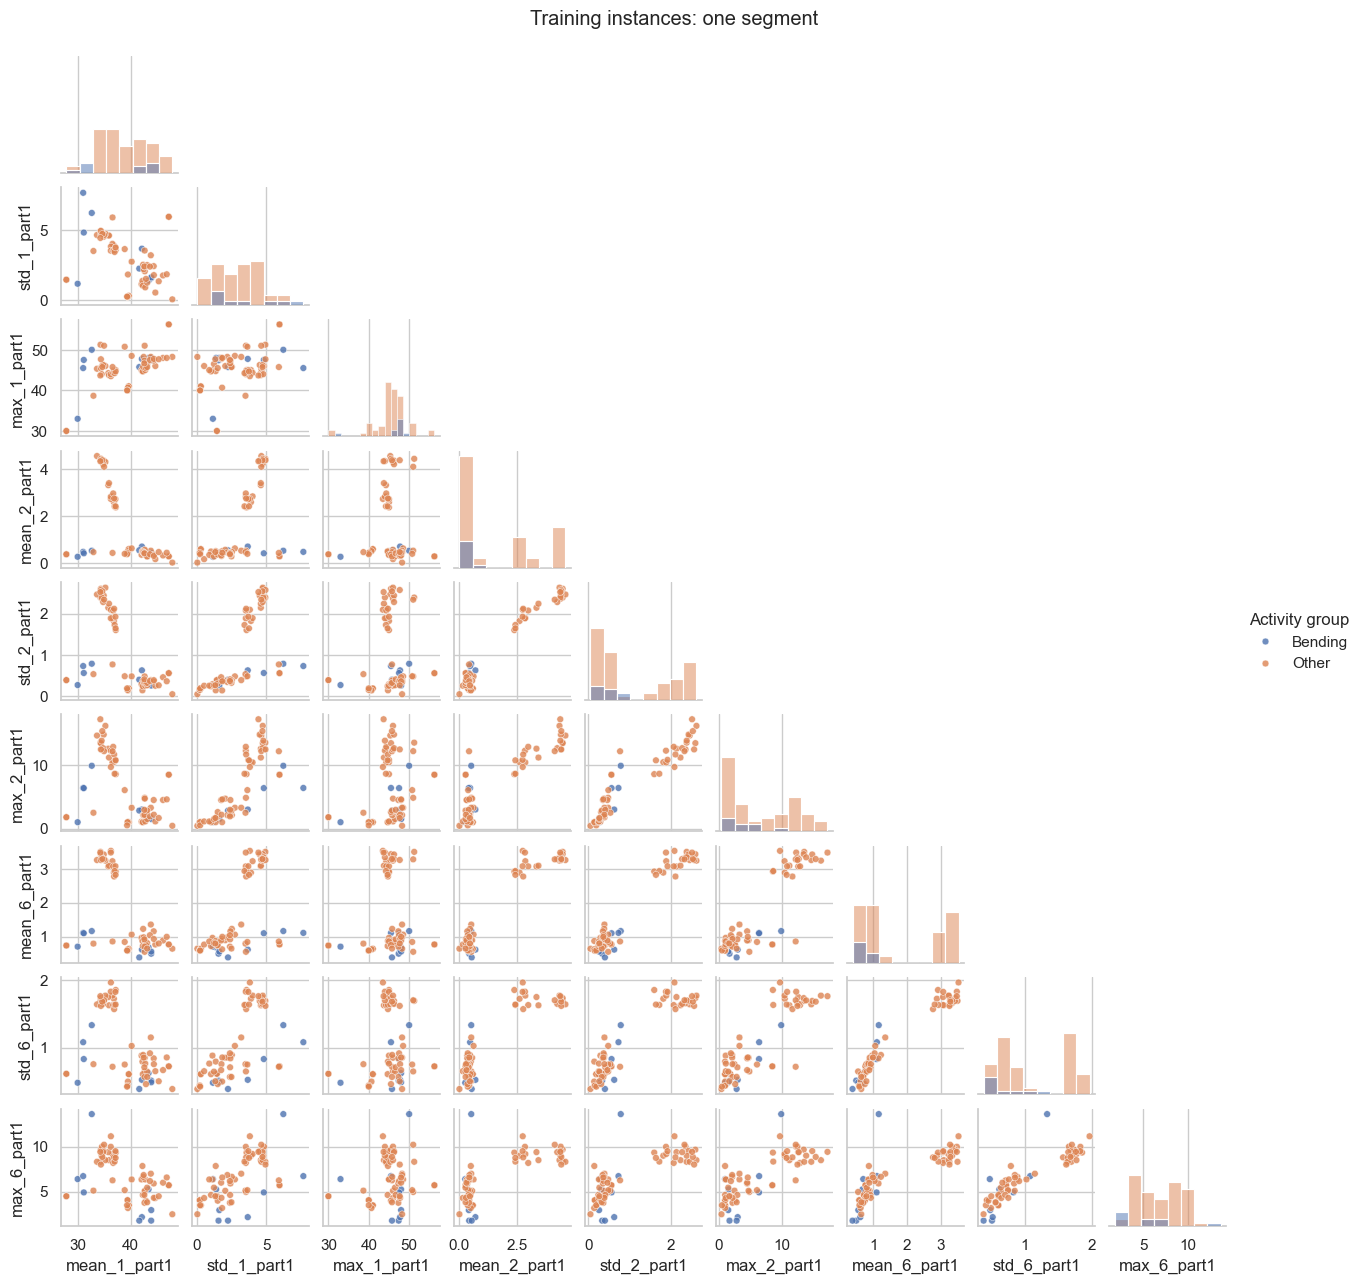

In [9]:
#2(a)i
plot_features = [
    f"{name}_{j}_part1"
    for j in [1, 2, 6] for name in ["mean", "std", "max"]
]
plot_df = train_features[1][plot_features].copy()
plot_df["Activity group"] = np.where(y_train_binary.eq(1), "Bending", "Other")
g = sns.pairplot(
    plot_df, hue="Activity group", corner=True, diag_kind="hist",
    height=1.4, plot_kws={"s": 24, "alpha": 0.8}
)
g.fig.suptitle("Training instances: one segment", y=1.02)
plt.show()

#### ii. Splitted Plots

### (a)ii
Splitting each series into two parts adds temporal information but does not produce a major qualitative improvement in these scatter plots. Bending instances often have low mean and standard deviation in series 2, yet still overlap some other activities. The two halves show broadly similar patterns; no single plotted pair separates every instance. The later RFE search also gives a lower best CV accuracy.

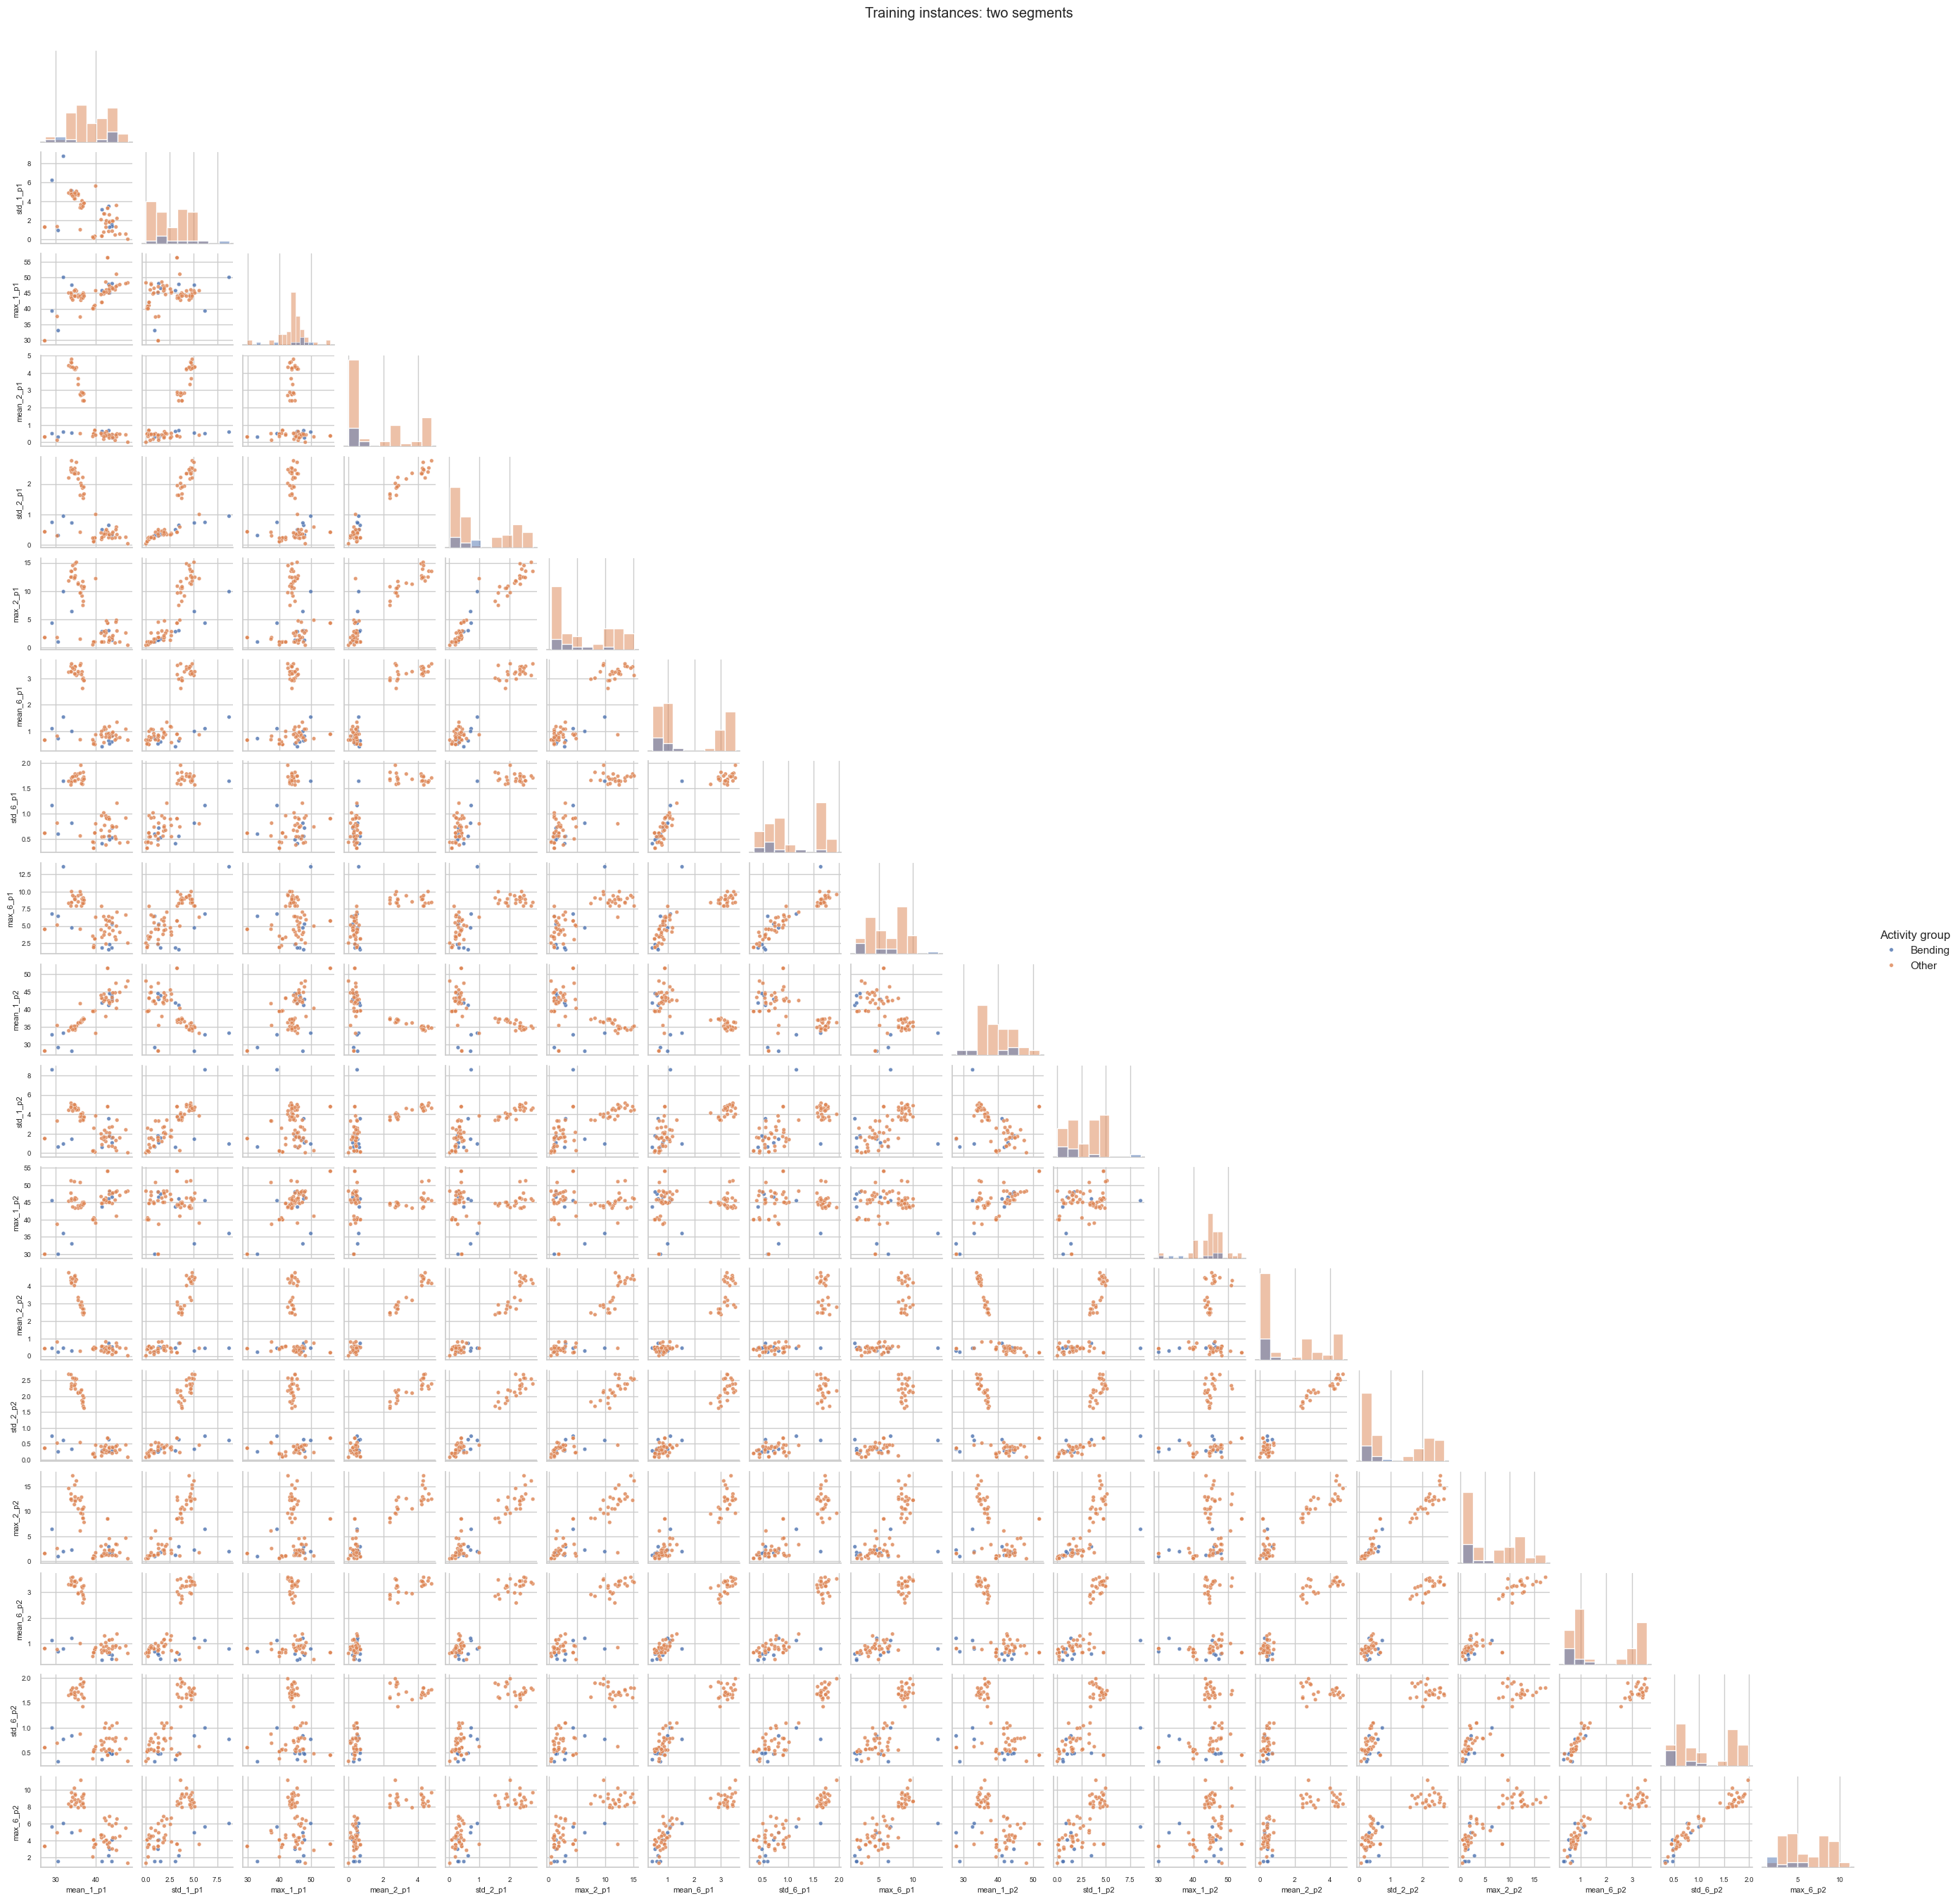

In [10]:
#2(a)ii
plot_features_two = [
    f"{name}_{j}_part{part}"
    for part in [1, 2] for j in [1, 2, 6]
    for name in ["mean", "std", "max"]
]
plot_df_two = train_features[2][plot_features_two].copy()
plot_df_two.columns = plot_df_two.columns.str.replace("_part", "_p", regex=False)
plot_df_two["Activity group"] = plot_df["Activity group"]
g = sns.pairplot(
    plot_df_two, hue="Activity group", corner=True, diag_kind="hist",
    height=1.5, plot_kws={"s": 16, "alpha": 0.8}
)
for ax in g.axes.flat:
    if ax is not None:
        ax.tick_params(labelsize=7)
        ax.set_xlabel(ax.get_xlabel(), fontsize=8)
        ax.set_ylabel(ax.get_ylabel(), fontsize=8)
g.fig.suptitle("Training instances: two segments", y=1.01)
plt.show()

#### iii. Time Series Segments

### (a)iii
I use RFE alternative to p-value pruning. All seven summaries from all six signals enter the candidate feature matrix, giving $42l$ features per instance.

I search every $l=1,\ldots,20$ and $p\in\{1,2,3,5,8,10,15,20\}$. This is an explicit candidate grid for $p$, not an exhaustive search of every integer up to $42l$. RFE removes 20% of the initial features per step to reduce computation. The classifier uses `C=1e6`, the large-$C$ approximation to unpenalized logistic regression allowed in the assignment.

Right way: split the original instances into stratified folds, fit the scaler and RFE on each training fold, and evaluate on its validation fold. Deterministic segmentation can be computed in advance because it does not learn from other instances. Stratification approximately preserves class proportions; there are nine bending and 60 other training instances.

Wrong way: select variables or standardize using all 69 training instances before CV, use the test set for selecting $l$ or $p$, or put segments of the same instance in different folds. The segments are features of one instance, not new independent samples. The maximum CV score is a tuning score and may be optimistic after searching many candidates; the held-out test set provides final evaluation.

In [11]:
#2(a)iii
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
binary_folds = list(cv.split(np.zeros(len(y_train_binary)), y_train_binary))
p_grid = [1, 2, 3, 5, 8, 10, 15, 20]
base_model = LogisticRegression(
    C=1e6, solver="liblinear", max_iter=3000, random_state=42
)
rfe_results = []

for l in range(1, 21):
    pipeline = Pipeline([
        ("scale", StandardScaler()),
        ("select", RFE(clone(base_model), step=0.2)),
        ("model", clone(base_model))
    ])
    search = GridSearchCV(
        pipeline, {"select__n_features_to_select": p_grid},
        cv=binary_folds, scoring="accuracy", n_jobs=2,
        refit=False, error_score="raise"
    )
    search.fit(train_features[l], y_train_binary)
    for params, mean_score, std_score in zip(
        search.cv_results_["params"], search.cv_results_["mean_test_score"],
        search.cv_results_["std_test_score"]
    ):
        rfe_results.append({
            "l": l, "p": params["select__n_features_to_select"],
            "CV accuracy": mean_score, "CV SD": std_score
        })
    print(f"l={l:2d}, best CV accuracy={max(search.cv_results_['mean_test_score']):.4f}")

rfe_results = pd.DataFrame(rfe_results).sort_values(
    ["CV accuracy", "l", "p"], ascending=[False, True, True]
).reset_index(drop=True)
best_l = int(rfe_results.loc[0, "l"])
best_p = int(rfe_results.loc[0, "p"])
selected_model = Pipeline([
    ("scale", StandardScaler()),
    ("select", RFE(clone(base_model), n_features_to_select=best_p, step=0.2)),
    ("model", clone(base_model))
]).fit(train_features[best_l], y_train_binary)
display(rfe_results.head(15).round(4))
print("Best (l, p):", (best_l, best_p))

l= 1, best CV accuracy=0.9857
l= 2, best CV accuracy=0.9286
l= 3, best CV accuracy=0.9857
l= 4, best CV accuracy=0.9571
l= 5, best CV accuracy=0.9703
l= 6, best CV accuracy=0.9857
l= 7, best CV accuracy=0.9418
l= 8, best CV accuracy=0.9429
l= 9, best CV accuracy=0.9429
l=10, best CV accuracy=0.9418
l=11, best CV accuracy=0.9418
l=12, best CV accuracy=0.9418
l=13, best CV accuracy=0.9132
l=14, best CV accuracy=0.9560
l=15, best CV accuracy=0.9286
l=16, best CV accuracy=0.9275
l=17, best CV accuracy=0.9714
l=18, best CV accuracy=0.9429
l=19, best CV accuracy=0.9571
l=20, best CV accuracy=0.9286


,l,p,CV accuracy,CV SD
0,1,10,0.9857,0.0286
1,1,15,0.9857,0.0286
2,3,1,0.9857,0.0286
3,6,8,0.9857,0.0286
4,1,5,0.9714,0.0350
5,1,8,0.9714,0.0350
6,1,20,0.9714,0.0350
7,6,10,0.9714,0.0571
8,17,15,0.9714,0.0350
9,5,15,0.9703,0.0364


Best (l, p): (1, 10)


#### iv. Confusion Matrix

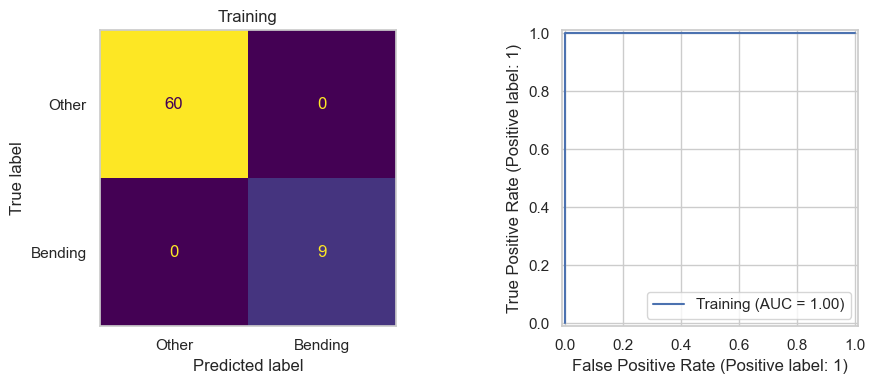

,Accuracy,Balanced accuracy,AUC
0,1.0,1.0,1.0


,Feature,Coefficient,p-value
0,Intercept,-14.6206,NaN
1,min_1_part1,-3.7815,NaN
2,q3_1_part1,-4.2032,NaN
3,max_2_part1,-1.8270,NaN
4,std_3_part1,-3.0591,NaN
5,max_4_part1,4.0618,NaN
6,q1_4_part1,-5.4258,NaN
7,min_5_part1,6.1237,NaN
8,max_5_part1,7.4237,NaN
9,mean_5_part1,3.1662,NaN


Complete separation: ordinary Wald p-values are unavailable.


In [12]:
#2(a)iv
def binary_report(y, probability, title):
    prediction = (probability >= 0.5).astype(int)

    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    ConfusionMatrixDisplay.from_predictions(
        y, prediction, display_labels=["Other", "Bending"],
        ax=axes[0], colorbar=False
    )
    axes[0].set_title(title)
    axes[0].grid(False)

    RocCurveDisplay.from_predictions(
        y, probability, ax=axes[1], name=title
    )
    plt.tight_layout()
    plt.show()

    return {
        "Accuracy": accuracy_score(y, prediction),
        "Balanced accuracy": balanced_accuracy_score(y, prediction),
        "AUC": roc_auc_score(y, probability)
    }


train_probability = selected_model.predict_proba(
    train_features[best_l]
)[:, 1]

rfe_train_metrics = binary_report(
    y_train_binary, train_probability, "Training"
)
display(pd.DataFrame([rfe_train_metrics]).round(4))

keep = selected_model.named_steps["select"].support_
selected_names = train_features[best_l].columns[keep]
logistic_model = selected_model.named_steps["model"]
x_selected = selected_model[:-1].transform(train_features[best_l])

coefficient_results = pd.DataFrame({
    "Feature": ["Intercept"] + selected_names.tolist(),
    "Coefficient": np.r_[
        logistic_model.intercept_[0], logistic_model.coef_[0]
    ],
    "p-value": np.nan
})

display(coefficient_results.round(4))
print("Complete separation: ordinary Wald p-values are unavailable.")

#### v. Test Classifier

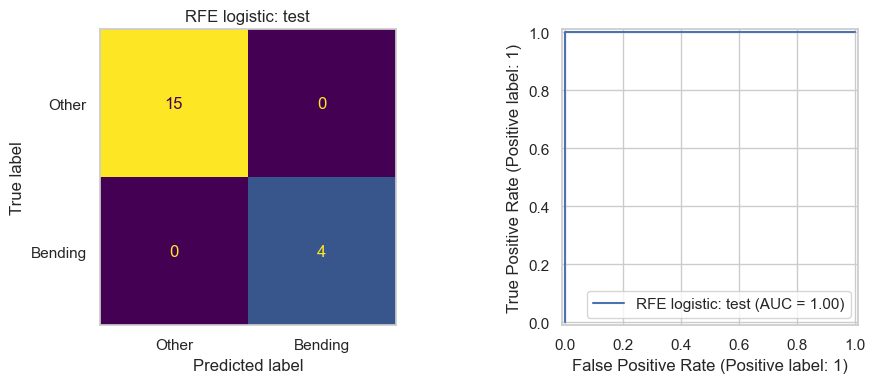

,CV accuracy,Test accuracy,Test balanced accuracy,Test AUC
0,0.9857,1.0,1.0,1.0


              precision    recall  f1-score   support

       Other       1.00      1.00      1.00        15
     Bending       1.00      1.00      1.00         4

    accuracy                           1.00        19
   macro avg       1.00      1.00      1.00        19
weighted avg       1.00      1.00      1.00        19



In [13]:
#2(a)v
x_test_selected = make_features(test_ids, best_l)
test_probability = selected_model.predict_proba(x_test_selected)[:, 1]
rfe_test_metrics = binary_report(y_test_binary, test_probability, "RFE logistic: test")
display(pd.DataFrame({
    "CV accuracy": [rfe_results.loc[0, "CV accuracy"]],
    "Test accuracy": [rfe_test_metrics["Accuracy"]],
    "Test balanced accuracy": [rfe_test_metrics["Balanced accuracy"]],
    "Test AUC": [rfe_test_metrics["AUC"]]
}).round(4))
print(classification_report(
    y_test_binary, test_probability >= 0.5,
    target_names=["Other", "Bending"], zero_division=0
))

#### vi. Separation

The selected features completely separate the training classes. As C increases and regularization weakens, the coefficient norm increases while training accuracy remains 100%. Under complete separation, the unpenalized logistic regression has no finite maximum-likelihood estimate, so ordinary Wald p-values are unavailable.

In [15]:
#2(a)vi
stability_results = []

for c in [1e2, 1e4, 1e6, 1e8]:
    model = LogisticRegression(
        C=c, solver="liblinear", max_iter=5000, random_state=42
    ).fit(x_selected, y_train_binary)

    stability_results.append({
        "C": c,
        "Coefficient norm": np.linalg.norm(model.coef_),
        "Train accuracy": model.score(x_selected, y_train_binary)
    })

display(pd.DataFrame(stability_results).round(4))

,C,Coefficient norm,Train accuracy
0,100.0,6.1259,1.0
1,10000.0,11.5742,1.0
2,1000000.0,14.6873,1.0
3,100000000.0,14.7768,1.0


#### vii. Imbalance

Training class counts:


Activity
Other      60
Bending     9
Name: count, dtype: int64

Sample prevalence: 0.5
Population prevalence estimate: 0.13043478260869565
Intercept adjustment: -1.8971


,Coefficient
Adjusted intercept,-11.2721
min_1_part1,-2.6330
q3_1_part1,-2.9428
max_2_part1,0.5748
std_3_part1,-1.1330
max_4_part1,1.4309
q1_4_part1,-3.9812
min_5_part1,4.0610
max_5_part1,4.4062
mean_5_part1,4.6360


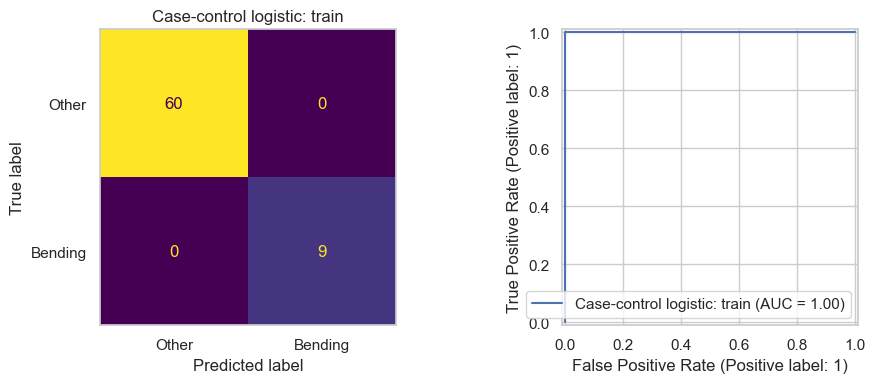

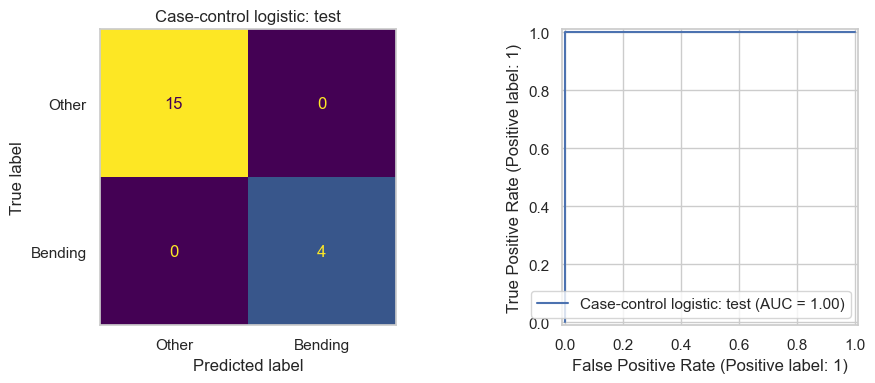

,Accuracy,Balanced accuracy,AUC
Train,1.0,1.0,1.0
Test,1.0,1.0,1.0


In [18]:
#2(a)vii
print("Training class counts:")
display(y_train_binary.value_counts().rename(index={0: "Other", 1: "Bending"}))

# Case-control sampling.
rng = np.random.default_rng(42)
case_indices = np.flatnonzero(y_train_binary.to_numpy() == 1)
control_indices = np.flatnonzero(y_train_binary.to_numpy() == 0)
sampled_controls = rng.choice(control_indices, size=len(case_indices), replace=False)
case_control_indices = np.r_[case_indices, sampled_controls]
case_control_model = clone(base_model).fit(
    x_selected[case_control_indices], y_train_binary.iloc[case_control_indices]
)

# Correct the sampled intercept back to the training population prevalence.
population_prevalence = y_train_binary.mean()
sample_prevalence = y_train_binary.iloc[case_control_indices].mean()
intercept_adjustment = logit(population_prevalence) - logit(sample_prevalence)
case_control_model.intercept_ += intercept_adjustment
print("Sample prevalence:", sample_prevalence)
print("Population prevalence estimate:", population_prevalence)
print("Intercept adjustment:", round(intercept_adjustment, 4))
display(pd.Series(
    np.r_[case_control_model.intercept_[0], case_control_model.coef_[0]],
    index=["Adjusted intercept"] + selected_names.tolist(), name="Coefficient"
).to_frame().round(4))
case_control_train = binary_report(
    y_train_binary, case_control_model.predict_proba(x_selected)[:, 1],
    "Case-control logistic: train"
)
case_control_test = binary_report(
    y_test_binary,
    case_control_model.predict_proba(selected_model[:-1].transform(x_test_selected))[:, 1],
    "Case-control logistic: test"
)
display(pd.DataFrame(
    [case_control_train, case_control_test], index=["Train", "Test"]
).round(4))

### (b) Binary Classification Using L1-penalized logistic regression

#### i. Time Series Segments

,l,C,CV accuracy,CV SD
0,2,10.0,0.9714,0.0350
1,10,100.0,0.9714,0.0350
2,12,1.0,0.9714,0.0350
3,12,10.0,0.9714,0.0350
4,1,1.0,0.9571,0.0571
5,1,10.0,0.9571,0.0350
6,1,100.0,0.9571,0.0350
7,2,1.0,0.9571,0.0350
8,3,1.0,0.9571,0.0350
9,6,10.0,0.9571,0.0350


Selected (l, C): (2, 10.0)
Nonzero coefficients: 10


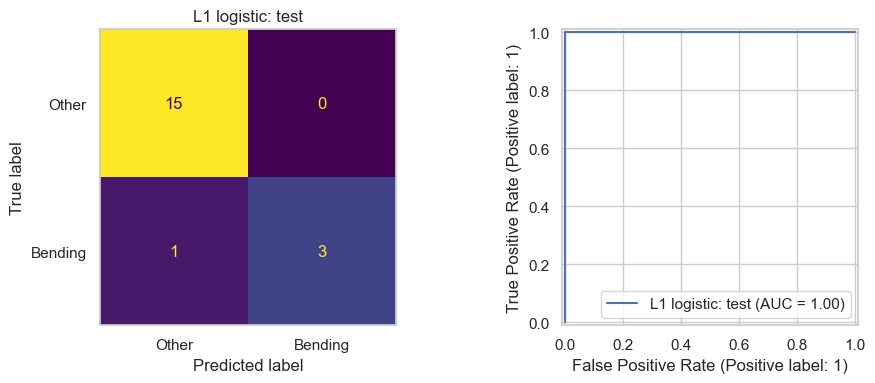

In [19]:
#2(b)i
c_grid = [0.01, 0.1, 1, 10, 100]
l1_results = []
for l in range(1, 21):
    pipeline = Pipeline([
        ("scale", StandardScaler()),
        ("model", LogisticRegression(
            **l1_options, solver="liblinear", max_iter=5000, random_state=42
        ))
    ])
    search = GridSearchCV(
        pipeline, {"model__C": c_grid}, cv=binary_folds,
        scoring="accuracy", n_jobs=2, refit=False, error_score="raise"
    ).fit(train_features[l], y_train_binary)
    for params, score, sd in zip(
        search.cv_results_["params"], search.cv_results_["mean_test_score"],
        search.cv_results_["std_test_score"]
    ):
        l1_results.append({"l": l, "C": params["model__C"], "CV accuracy": score, "CV SD": sd})

l1_results = pd.DataFrame(l1_results).sort_values(
    ["CV accuracy", "l", "C"], ascending=[False, True, True]
).reset_index(drop=True)
best_l_l1 = int(l1_results.loc[0, "l"])
best_c_l1 = float(l1_results.loc[0, "C"])
l1_model = Pipeline([
    ("scale", StandardScaler()),
    ("model", LogisticRegression(
        **l1_options, C=best_c_l1, solver="liblinear",
        max_iter=5000, random_state=42
    ))
]).fit(train_features[best_l_l1], y_train_binary)
display(l1_results.head(10).round(4))
print("Selected (l, C):", (best_l_l1, best_c_l1))
print("Nonzero coefficients:", np.count_nonzero(l1_model.named_steps["model"].coef_))
l1_test_metrics = binary_report(
    y_test_binary, l1_model.predict_proba(make_features(test_ids, best_l_l1))[:, 1],
    "L1 logistic: test"
)

#### ii. Comparison

In [20]:
#2(b)ii
binary_comparison = pd.DataFrame([
    {"Method": "Large-C logistic + RFE", "l": best_l,
     "CV accuracy": rfe_results.loc[0, "CV accuracy"], **rfe_test_metrics},
    {"Method": "L1 logistic", "l": best_l_l1,
     "CV accuracy": l1_results.loc[0, "CV accuracy"], **l1_test_metrics}
]).set_index("Method")
display(binary_comparison.round(4))
cv_winner = binary_comparison["CV accuracy"].idxmax()
print("Preferred by training CV:", cv_winner)
print("Test accuracies are final comparisons, not tuning criteria.")

,l,CV accuracy,Accuracy,Balanced accuracy,AUC
Method,,,,,
Large-C logistic + RFE,1,0.9857,1.0000,1.000,1.0
L1 logistic,2,0.9714,0.9474,0.875,1.0


Preferred by training CV: Large-C logistic + RFE
Test accuracies are final comparisons, not tuning criteria.


### (c) Multi-class Classification (The Realistic Case)

#### i. Time Series Segments

/opt/anaconda3/lib/python3.12/site-packages/sklearn/model_selection/_split.py:737: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


,l,C,CV accuracy
0,2,100,0.9286
1,1,1,0.8846
2,5,100,0.8703
3,4,100,0.8560
4,8,100,0.8560
5,18,10,0.8560
6,6,10,0.8418
7,9,100,0.8418
8,17,1,0.8418
9,20,1,0.8407


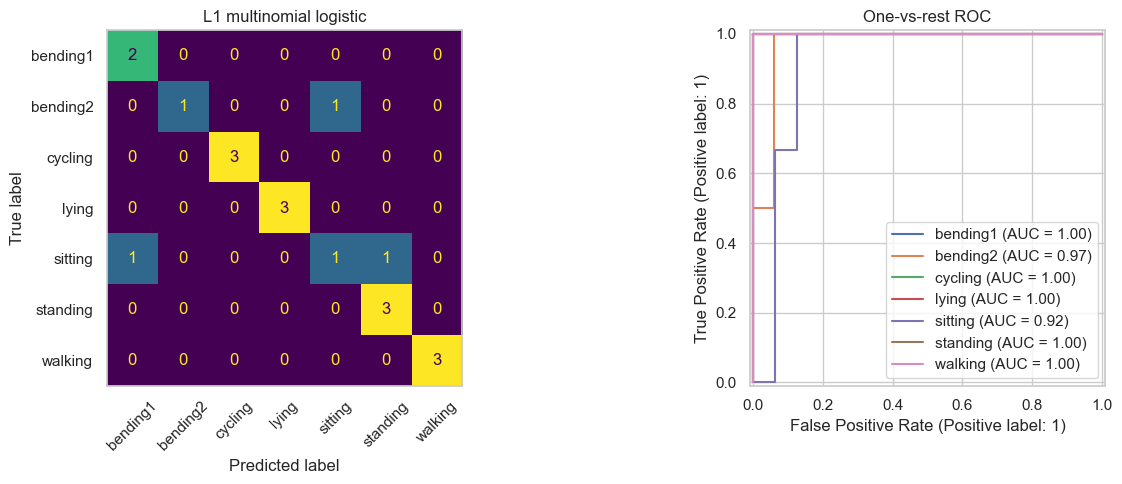

,Test accuracy,Test error,Test balanced accuracy,Macro OvR AUC
0,0.8421,0.1579,0.8333,0.9839


In [21]:
#2(c)i
multiclass_folds = list(cv.split(train_features[1], y_train))

pipeline = Pipeline([
    ("scale", StandardScaler()),
    ("model", LogisticRegression(
        **l1_options, solver="saga",
        max_iter=10000, tol=1e-3, random_state=42
    ))
])

multiclass_results = []

for l in range(1, 21):
    search = GridSearchCV(
        pipeline, {"model__C": c_grid},
        cv=multiclass_folds, scoring="accuracy",
        n_jobs=2, refit=False
    )
    search.fit(train_features[l], y_train)

    multiclass_results.append({
        "l": l,
        "C": search.best_params_["model__C"],
        "CV accuracy": search.best_score_
    })

multiclass_results = pd.DataFrame(multiclass_results).sort_values(
    ["CV accuracy", "l", "C"], ascending=[False, True, True]
).reset_index(drop=True)

display(multiclass_results.round(4))

best_l_multi = int(multiclass_results.loc[0, "l"])
best_c_multi = float(multiclass_results.loc[0, "C"])

multiclass_model = clone(pipeline)
multiclass_model.set_params(model__C=best_c_multi)
multiclass_model.fit(train_features[best_l_multi], y_train)


def multiclass_report(model, x_test, title):
    prediction = model.predict(x_test)
    probability = model.predict_proba(x_test)
    classes = model.classes_
    indicators = label_binarize(y_test, classes=classes)

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    ConfusionMatrixDisplay.from_predictions(
        y_test, prediction, labels=classes,
        xticks_rotation=45, ax=axes[0], colorbar=False
    )
    axes[0].set_title(title)
    axes[0].grid(False)

    for j, activity in enumerate(classes):
        RocCurveDisplay.from_predictions(
            indicators[:, j], probability[:, j],
            name=activity, ax=axes[1]
        )

    axes[1].set_title("One-vs-rest ROC")
    plt.tight_layout()
    plt.show()

    accuracy = accuracy_score(y_test, prediction)

    return {
        "Test accuracy": accuracy,
        "Test error": 1 - accuracy,
        "Test balanced accuracy": balanced_accuracy_score(y_test, prediction),
        "Macro OvR AUC": roc_auc_score(
            y_test, probability, labels=classes,
            multi_class="ovr", average="macro"
        )
    }


multi_metrics = multiclass_report(
    multiclass_model,
    make_features(test_ids, best_l_multi),
    "L1 multinomial logistic"
)

display(pd.DataFrame([multi_metrics]).round(4))

#### ii. Naive Bayes

Gaussian NB {'Method': 'Gaussian NB', 'l': 1, 'Parameter': 0.1, 'CV accuracy': 0.9131868131868132}


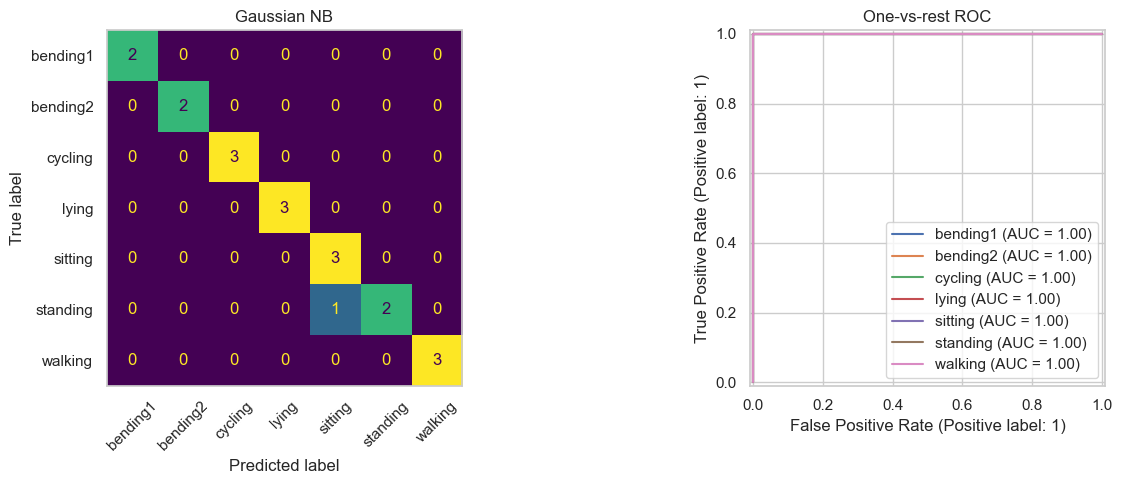

Multinomial NB {'Method': 'Multinomial NB', 'l': 1, 'Parameter': 1, 'CV accuracy': 0.8549450549450549}


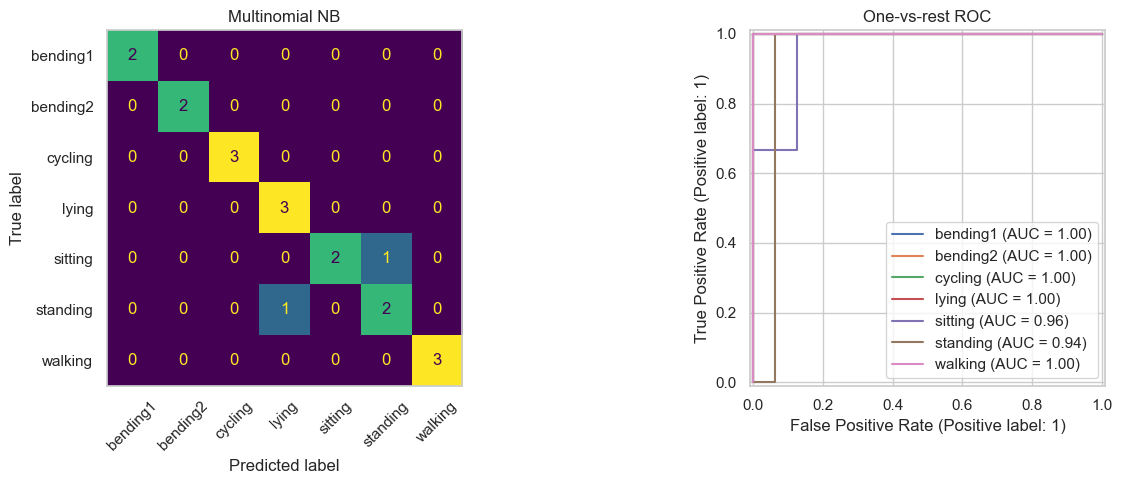

,Test accuracy,Test error,Test balanced accuracy,Macro OvR AUC
Gaussian NB,0.9474,0.0526,0.9524,1.0000
Multinomial NB,0.8947,0.1053,0.9048,0.9851


In [23]:
#2(c)ii
nb_results = []
nb_best = {}
nb_metrics = {}

for name in ["Gaussian NB", "Multinomial NB"]:
    if name == "Gaussian NB":
        model = Pipeline([
            ("scale", StandardScaler()),
            ("model", GaussianNB())
        ])
        parameter = "model__var_smoothing"
        values = [1e-9, 1e-7, 1e-5, 1e-3, 0.1]
    else:
        model = Pipeline([("model", MultinomialNB())])
        parameter = "model__alpha"
        values = [0.01, 0.1, 1, 10, 100]

    best_score = -1

    for l in range(1, 21):
        search = GridSearchCV(
            model, {parameter: values},
            cv=multiclass_folds, scoring="accuracy", n_jobs=2
        )
        search.fit(train_features[l], y_train)

        result = {
            "Method": name,
            "l": l,
            "Parameter": search.best_params_[parameter],
            "CV accuracy": search.best_score_
        }
        nb_results.append(result)

        if search.best_score_ > best_score:
            best_score = search.best_score_
            best_model = search.best_estimator_
            nb_best[name] = result

    best_l = nb_best[name]["l"]
    print(name, nb_best[name])

    nb_metrics[name] = multiclass_report(
        best_model, make_features(test_ids, best_l), name
    )

nb_results = pd.DataFrame(nb_results)
display(pd.DataFrame(nb_metrics).T.round(4))

#### ii. Comparison

On the held-out test set, GaussianNB performs best.Training CV instead favors multinomial logistic regression. Overall, I would have chosen logistic regression before seeing the test labels, while GaussianNB has the lowest observed test error in this experiment. With only 19 test instances, these results do not establish a universal ranking.

## 3. ISLR 4.8.3

For class $k$, let $X\mid Y=k\sim N(\mu_k,\sigma_k^2)$ and $P(Y=k)=\pi_k$. Bayes' rule classifies $x$ into the class maximizing $\pi_k f_k(x)$. Taking logs and dropping the common constant $-\tfrac12\log(2\pi)$ gives

$$\delta_k(x)=\log\pi_k-\log\sigma_k-\frac{(x-\mu_k)^2}{2\sigma_k^2}.$$

Expanding,

$$\delta_k(x)=-\frac{x^2}{2\sigma_k^2}+\frac{\mu_k}{\sigma_k^2}x-\frac{\mu_k^2}{2\sigma_k^2}-\log\sigma_k+\log\pi_k.$$

The boundary between classes $k$ and $j$ solves

$$\left(\frac1{2\sigma_j^2}-\frac1{2\sigma_k^2}\right)x^2+
\left(\frac{\mu_k}{\sigma_k^2}-\frac{\mu_j}{\sigma_j^2}\right)x+
\log\frac{\pi_k\sigma_j}{\pi_j\sigma_k}
-\frac{\mu_k^2}{2\sigma_k^2}+\frac{\mu_j^2}{2\sigma_j^2}=0.$$

When the class variances differ, the quadratic term generally remains, so the discriminant comparison is quadratic. In one dimension this can produce two thresholds. Equal variances cancel the quadratic term and recover the linear discriminant special case.

## 4. ISLR 4.8.7

Let $Y=\text{Yes}$ mean that a company issues a dividend. The supplied quantities are $\pi_{\text{Yes}}=0.8$, $\pi_{\text{No}}=0.2$, $\mu_{\text{Yes}}=10$, $\mu_{\text{No}}=0$, and common variance $36$.

At $X=4$, Bayes' rule gives

$$P(Y=\text{Yes}\mid X=4)=
\frac{0.8\exp[-(4-10)^2/72]}
{0.8\exp[-(4-10)^2/72]+0.2\exp[-(4-0)^2/72]}\approx 0.7519.$$

Thus the estimated probability is **75.19%**, and a classifier with threshold 0.5 predicts that the company issues a dividend.

In [22]:
probability_yes = expit(np.log(0.8 / 0.2) + (2 * 4 * 10 - 10**2) / (2 * 36))
print(f"P(dividend = Yes | X = 4): {probability_yes:.6f}")

P(dividend = Yes | X = 4): 0.751852


## 5.1. Extra Practice ISLR 4.8.4

## 5.2. Extra Practice ISLR 4.8.9